# 13 双ID隔离后的临床重验与扩展

用户已批准本步。先阅读固定方案`reports/ucsd_clinical_revalidation_protocol.md`。隔离0036和0038共5次扫描，比较同一238次扫描/176名源患者上的M0（年龄、性别）与M1（另加初始事件间隔及其他扫描前治疗）。不使用分子、未来随访或MRI参考掩膜。

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_clinical_revalidation import run,EXCLUDED_IDS
summary=run(ROOT)
d=pd.read_csv(ROOT/'data/processed/ucsd_clinical_revalidated_oof.csv')
excluded=pd.read_csv(ROOT/'reports/ucsd_clinical_revalidation/excluded_identity_conflicts.csv')
assert len(d)==238 and d.patient_id.nunique()==176
assert sorted(excluded.ID)==EXCLUDED_IDS
display(d.groupby('tumor_label').agg(timepoints=('ID','size'),patients=('patient_id','nunique')))
display(excluded)

,timepoints,patients
tumor_label,,
0,51,39
1,187,148


,ID,patient_id,BraTS ID,brats_patient_id,tumor_label,reason
0,UCSD-PTGBM-0036_01,UCSD-PTGBM-0036,BraTS-GLI-02289-100,BraTS-GLI-02289,1,dual_identifier_mapping_conflict; not outcome/...
1,UCSD-PTGBM-0036_02,UCSD-PTGBM-0036,BraTS-GLI-02289-101,BraTS-GLI-02289,1,dual_identifier_mapping_conflict; not outcome/...
2,UCSD-PTGBM-0038_01,UCSD-PTGBM-0038,BraTS-GLI-02291-100,BraTS-GLI-02291,1,dual_identifier_mapping_conflict; not outcome/...
3,UCSD-PTGBM-0038_02,UCSD-PTGBM-0038,BraTS-GLI-02291-101,BraTS-GLI-02291,1,dual_identifier_mapping_conflict; not outcome/...
4,UCSD-PTGBM-0038_03,UCSD-PTGBM-0038,BraTS-GLI-02289-102,BraTS-GLI-02289,1,dual_identifier_mapping_conflict; not outcome/...


## 重新建立患者分组并核查预处理

M0、M1与训练折比例对照使用同一病例及5折，固定种子20261029。两个患者ID体系均不跨折。M1的log初始事件间隔只用训练折中位数填补，另保留缺失标记；这是4项临床变量、5个非截距系数。

In [2]:
folds=json.loads((ROOT/'reports/ucsd_clinical_revalidation/fold_audit.json').read_text())
for f in folds:
    tr=d[d.validation_fold.ne(f['fold'])];te=d[d.validation_fold.eq(f['fold'])]
    for key in ['patient_id','brats_patient_id','validation_group']:
        assert set(tr[key]).isdisjoint(te[key])
    assert set(te.ID)==set(f['test_IDs'])
    for model in ['M0','M1']:
        assert np.isclose(f['models'][model]['parameters']['age_mean'],tr.age_years.mean())
    median=np.nanmedian(tr.log_initial_event_days)
    assert np.isclose(f['models']['M1']['parameters']['log_interval_impute_median'],median)
    assert np.allclose(te.prior_oof_probability,tr.tumor_label.mean())
assert d.groupby('patient_id').validation_fold.nunique().eq(1).all()
assert d.groupby('brats_patient_id').validation_fold.nunique().eq(1).all()
display(pd.read_csv(ROOT/'reports/ucsd_clinical_revalidation/fold_metrics.csv'))

,fold,model,n_train,n_test,n_test_patients,test_tumor,test_treatment_change,roc_auc,ap_tumor,ap_treatment_change,brier,sensitivity_tumor,specificity_treatment_change,balanced_accuracy,accuracy,tn,fp,fn,tp
0,1,M0,190,48,35,38,10,0.615789,0.866165,0.352647,0.158966,1.000000,0.000000,0.500000,0.791667,0,10,0,38
1,1,M1,190,48,35,38,10,0.765789,0.905482,0.535886,0.139683,1.000000,0.000000,0.500000,0.791667,0,10,0,38
2,2,M0,189,49,38,38,11,0.557416,0.796844,0.518103,0.163601,1.000000,0.000000,0.500000,0.775510,0,11,0,38
3,2,M1,189,49,38,38,11,0.764354,0.872303,0.562908,0.142054,1.000000,0.181818,0.590909,0.816327,2,9,0,38
4,3,M0,191,47,35,37,10,0.697297,0.861352,0.369599,0.159437,1.000000,0.000000,0.500000,0.787234,0,10,0,37
5,3,M1,191,47,35,37,10,0.643243,0.833261,0.533133,0.159178,1.000000,0.200000,0.600000,0.829787,2,8,0,37
6,4,M0,191,47,33,37,10,0.571622,0.857832,0.281572,0.170920,1.000000,0.000000,0.500000,0.787234,0,10,0,37
7,4,M1,191,47,33,37,10,0.572973,0.832501,0.345372,0.179669,0.891892,0.100000,0.495946,0.723404,1,9,4,33
8,5,M0,191,47,35,37,10,0.609459,0.850738,0.339372,0.167072,1.000000,0.000000,0.500000,0.787234,0,10,0,37
9,5,M1,191,47,35,37,10,0.686486,0.870346,0.459927,0.153679,1.000000,0.000000,0.500000,0.787234,0,10,0,37


## 主分析结果与成对差值

所有性能来自折外预测。患者整簇bootstrap 2000次，在相同抽样上比较M1−M0；区间条件于固定OOF预测，不包含全部重训/重划折变异。阈值固定0.5，没有通过阈值优化或模型搜索抬高成绩。

In [3]:
display(pd.DataFrame(summary['metrics']).T)
print('95% intervals:',json.dumps(summary['patient_cluster_bootstrap_95ci'],indent=2))
print('Paired M1 minus M0:',summary['paired_differences_M1_minus_M0'])
assert summary['same_cases_and_folds_for_models']
assert summary['hyperparameter_search'] is False and summary['external_validation'] is False

,roc_auc,ap_tumor,ap_treatment_change,brier,sensitivity_tumor,specificity_treatment_change,balanced_accuracy,accuracy,tn,fp,fn,tp
M0,0.612352,0.844232,0.310379,0.163975,1.00000,0.000000,0.500000,0.785714,0.0,51.0,0.0,187.0
M1,0.678987,0.860253,0.406353,0.154681,0.97861,0.098039,0.538324,0.789916,5.0,46.0,4.0,183.0
prior,0.492188,0.782748,0.211562,0.168385,1.00000,0.000000,0.500000,0.785714,0.0,51.0,0.0,187.0


95% intervals: {
  "M0": {
    "roc_auc": {
      "lower": 0.512186967855178,
      "upper": 0.7147247959877592
    },
    "ap_tumor": {
      "lower": 0.7793503199877028,
      "upper": 0.9087843658678272
    },
    "ap_treatment_change": {
      "lower": 0.21140761361674598,
      "upper": 0.47213926986268645
    },
    "brier": {
      "lower": 0.1291507688904672,
      "upper": 0.1989034403143975
    }
  },
  "M1": {
    "roc_auc": {
      "lower": 0.5726532718684241,
      "upper": 0.7749659010903029
    },
    "ap_tumor": {
      "lower": 0.7964962052939404,
      "upper": 0.9207172666082172
    },
    "ap_treatment_change": {
      "lower": 0.26558037576447796,
      "upper": 0.5804192437479795
    },
    "brier": {
      "lower": 0.12250917048588618,
      "upper": 0.18679318637372416
    }
  },
  "M1_minus_M0": {
    "roc_auc": {
      "lower": -0.04988594782321421,
      "upper": 0.17022191032641829
    },
    "brier": {
      "lower": -0.023804082971552416,
      "upper": 0.

## 完整间隔资料敏感性分析与解释

预先指定的唯一敏感性分析，仅保留有严格扫描前初始事件间隔的记录，对该子集重新分组拟合M0/M1。子集结果不能替换主分析，跨人群AUC也不作为模型增益。缺失标记可能反映回顾性记录模式，不能赋予生物学因果含义。最终全队列系数仅供重建，不报告其训练性能。

In [4]:
display(pd.crosstab(d.initial_event_missing,d.tumor_label,rownames=['Initial interval missing'],colnames=['Tumor label']))
print(json.dumps(summary['secondary_complete_interval'],indent=2))
print('Full-cohort reconstruction parameters:',json.dumps(summary['final_full_cohort_parameters'],indent=2))
assert summary['molecular_features_used'] is False and summary['MRI_used'] is False

{
  "timepoints": 192,
  "source_patients": 142,
  "tumor_timepoints": 145,
  "treatment_change_timepoints": 47,
  "metrics": {
    "M0": {
      "roc_auc": 0.521129860601614,
      "ap_tumor": 0.7780976308817679,
      "ap_treatment_change": 0.30013946200225994,
      "brier": 0.18476593978107744,
      "sensitivity_tumor": 1.0,
      "specificity_treatment_change": 0.0,
      "balanced_accuracy": 0.5,
      "accuracy": 0.7552083333333334,
      "tn": 0,
      "fp": 47,
      "fn": 0,
      "tp": 145
    },
    "M1": {
      "roc_auc": 0.6225972120322817,
      "ap_tumor": 0.8002055483329484,
      "ap_treatment_change": 0.38892466583517604,
      "brier": 0.17851220674160095,
      "sensitivity_tumor": 0.9655172413793104,
      "specificity_treatment_change": 0.0851063829787234,
      "balanced_accuracy": 0.5253118121790169,
      "accuracy": 0.75,
      "tn": 4,
      "fp": 43,
      "fn": 5,
      "tp": 140
    },
    "prior": {
      "roc_auc": 0.48041085840058695,
      "ap_tumor

Tumor label,0,1
Initial interval missing,,
0,47,145
1,4,42


## MRI重试与阶段边界

两例实际FLAIR文件的传输尝试独立于临床拟合。读取本步保存收据，公开下载参数不等同下载像素；临床与未来MRI模型的增量比较仍需在共同病例上重跑。

临床模型比较图：

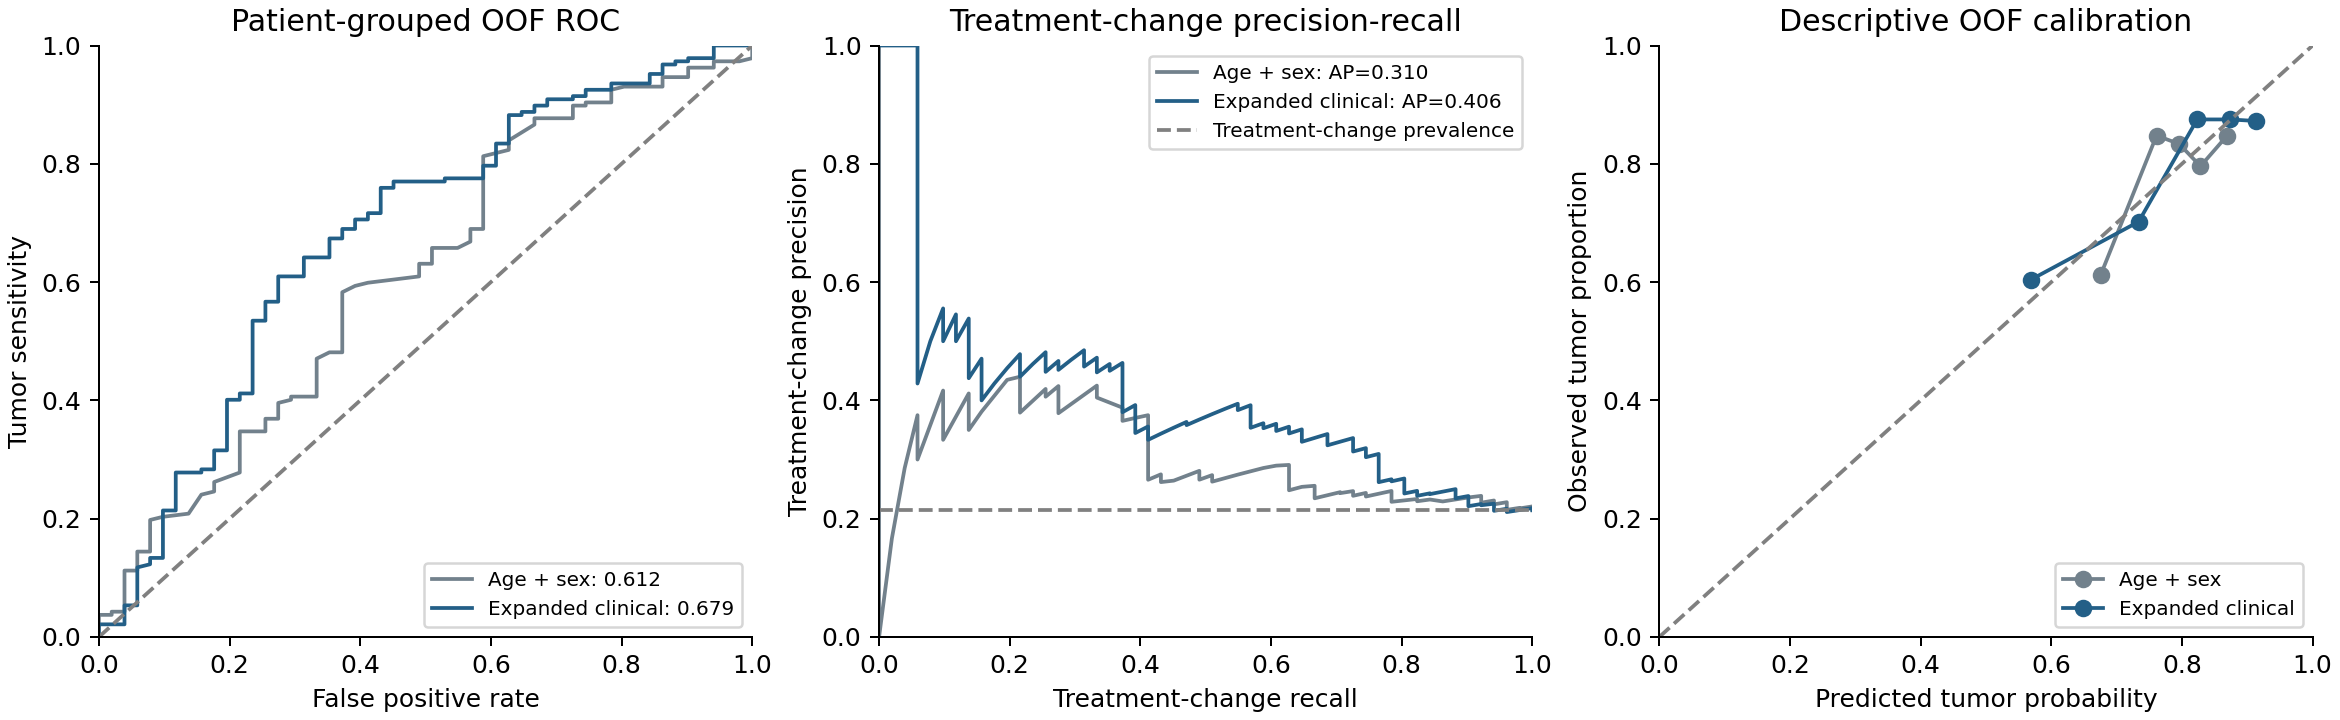

In [5]:
receipt=ROOT/'reports/ucsd_clinical_revalidation/mri_sample_transfer_retry.json'
if receipt.exists():
    mri=json.loads(receipt.read_text());print(json.dumps(mri,indent=2))
    assert mri['source_NIfTI_files_downloaded']==0
assert summary['next_step_requires_user_approval'] is True
print('Clinical comparison completed under the fixed protocol. Next stage awaits user approval.')

{
  "date": "2026-10-29",
  "checked_at_utc": "2026-10-29T04:09:53.097660+00:00",
  "purpose": "Two selected FLAIR files only; not a whole-package transfer",
  "source_NIfTI_files_downloaded": 0,
  "source_NIfTI_bytes_downloaded": 0,
  "pixel_QC_complete": false,
  "symlink_targets_resolved": false,
  "local_ascp_available": false,
  "public_link_authorization_http_status": 201,
  "http_gateway_url": null,
  "requested_files": [
    "/UCSD-PTGBM-BraTS-2024-test-set/UCSD-PTGBM-0001_01/UCSD-PTGBM-0001_01_FLAIR.nii.gz",
    "/UCSD-PTGBM-BraTS-2024-test-set/UCSD-PTGBM-0003_01/UCSD-PTGBM-0003_01_FLAIR.nii.gz"
  ],
  "download_parameter_http_status": 201,
  "transfer_parameter_paths": [
    "/UCSD-PTGBM-BraTS-2024-test-set - 416ac7dc-014a-4d67-9646-c5e6dee6db47.aspera-package/PKG - UCSD-PTGBM-BraTS-2024-test-set/UCSD-PTGBM-BraTS-2024-test-set/UCSD-PTGBM-0001_01/UCSD-PTGBM-0001_01_FLAIR.nii.gz",
    "/UCSD-PTGBM-BraTS-2024-test-set - 416ac7dc-014a-4d67-9646-c5e6dee6db47.aspera-package/PKG - U